In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [3]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5), (0.5))
    ])

transform = transforms.ToTensor()

mnist_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

data_loader = torch.utils.data.DataLoader(dataset=mnist_data,
                                          batch_size=64,
                                          shuffle=True)

mnist_data_valid = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

data_loader_valid = torch.utils.data.DataLoader(dataset=mnist_data_valid,
                                          batch_size=64,
                                          shuffle=True)             

In [4]:
dataiter = iter(data_loader)
images, labels = next(dataiter)
print(torch.min(images), torch.max(images))

tensor(0.) tensor(1.)


In [5]:
# repeatedly reduce the size
class Autoencoder_Linear(nn.Module):
    def __init__(self):
        super().__init__()        
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128), # (N, 784) -> (N, 128)
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, 3) # -> N, 3
        )
        
        self.decoder = nn.Sequential(
            nn.Linear(3, 12),
            nn.ReLU(),
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded
    
# Input [-1, +1] -> use nn.Tanh

In [6]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()        
        # N, 1, 28, 28
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), # -> N, 16, 14, 14
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), # -> N, 32, 7, 7
            nn.ReLU(),
            nn.Conv2d(32, 64, 7) # -> N, 64, 1, 1
        )
        
        # N , 64, 1, 1
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 7), # -> N, 32, 7, 7
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), # N, 16, 14, 14 (N,16,13,13 without output_padding)
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), # N, 1, 28, 28  (N,1,27,27)
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [7]:
# model = Autoencoder()  # Usa este para autoencoder convolutivo para la práctica
model = Autoencoder_Linear()

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(),
                             lr=1e-3, 
                             weight_decay=1e-5)

In [8]:
# Point to training loop video
num_epochs = 10
outputs = []
for epoch in range(num_epochs):
    for (img, _) in data_loader:
        img = img.reshape(-1, 28*28) # -> use for Autoencoder_Linear
        recon = model(img)
        loss = criterion(recon, img)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f'Epoch:{epoch+1}, Loss:{loss.item():.4f}')
    outputs.append((epoch, img, recon))

Epoch:1, Loss:0.0462
Epoch:2, Loss:0.0400
Epoch:3, Loss:0.0389
Epoch:4, Loss:0.0384
Epoch:5, Loss:0.0406
Epoch:6, Loss:0.0388
Epoch:7, Loss:0.0356
Epoch:8, Loss:0.0342
Epoch:9, Loss:0.0352
Epoch:10, Loss:0.0350


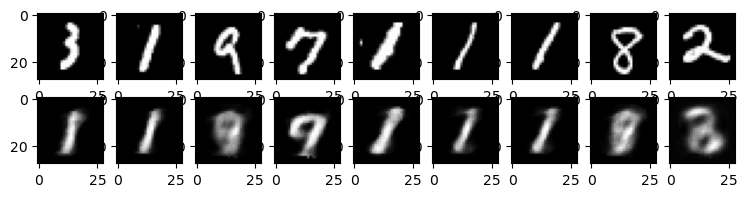

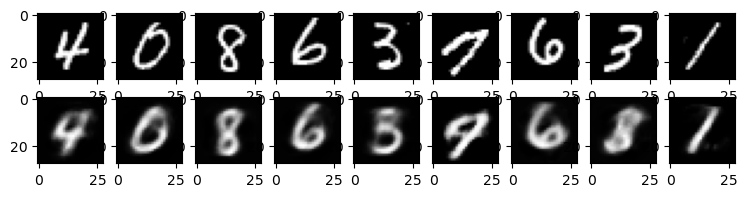

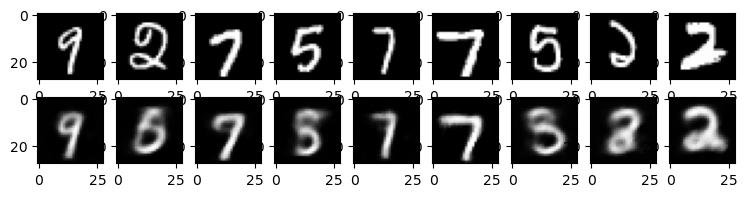

In [9]:
for k in range(0, num_epochs, 4):
    plt.figure(figsize=(9, 2))
    plt.gray()
    
    imgs = outputs[k][1].detach().numpy()
    recon = outputs[k][2].detach().numpy()

    for i, item in enumerate(imgs):
        if i >= 9: break
        plt.subplot(2, 9, i+1)
        item = item.reshape(-1, 28,28) # -> use for Autoencoder_Linear
        # item: 1, 28, 28
        plt.imshow(item[0])
            
    for i, item in enumerate(recon):
        if i >= 9: break
        plt.subplot(2, 9, 9+i+1) # row_length + i + 1
        item = item.reshape(-1, 28,28) # -> use for Autoencoder_Linear
        # item: 1, 28, 28
        plt.imshow(item[0])

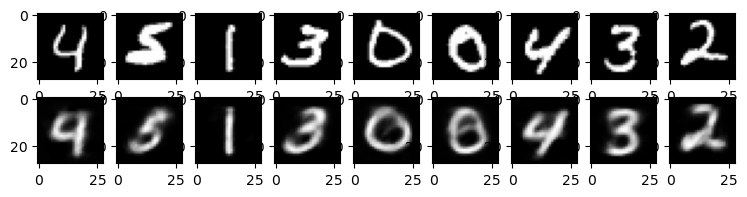

In [10]:
model.eval()

dataiter = iter(data_loader_valid)
images, labels = next(dataiter)

img = images[0]

plt.figure(figsize=(9, 2))
plt.gray()


for i, img in enumerate(images[:9]):
    with torch.no_grad():
        img2 = img.reshape(-1, 28*28) # -> use for Autoencoder_Linear
        pred = model(img2)
        recon = pred[0].detach().numpy()
        recon2 = recon.reshape(-1, 28,28) # -> use for Autoencoder_Linear

        plt.subplot(2, 9, i+1)
        plt.imshow(img[0])

        plt.subplot(2, 9, i+1+9)
        plt.imshow(recon2[0])

In [11]:
def add_noise(img, noise_factor=0.5):
    noisy = img + noise_factor * torch.randn_like(img)
    noisy = torch.clamp(noisy, 0., 1.)
    return noisy

In [12]:
def entrenar_ruido(model, num_epochs=10):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    train_losses, val_losses = [], []
    for epoch in range(num_epochs):
        model.train()
        total = 0
        for (img, _) in data_loader:
            recon = model(add_noise(img))
            loss = criterion(recon, img)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
        train_losses.append(total / len(data_loader))

        model.eval()
        total = 0
        with torch.no_grad():
            for (img, _) in data_loader_valid:
                recon = model(add_noise(img))
                total += criterion(recon, img).item()
        val_losses.append(total / len(data_loader_valid))

        print(f'Epoch:{epoch+1}, Loss:{train_losses[-1]:.4f}, Val Loss:{val_losses[-1]:.4f}')
    return train_losses, val_losses

model_ruido = Autoencoder()
train_losses, val_losses = entrenar_ruido(model_ruido)

Epoch:1, Loss:0.0423, Val Loss:0.0190
Epoch:2, Loss:0.0165, Val Loss:0.0144
Epoch:3, Loss:0.0139, Val Loss:0.0131
Epoch:4, Loss:0.0128, Val Loss:0.0121
Epoch:5, Loss:0.0122, Val Loss:0.0118
Epoch:6, Loss:0.0119, Val Loss:0.0117
Epoch:7, Loss:0.0117, Val Loss:0.0114
Epoch:8, Loss:0.0115, Val Loss:0.0113
Epoch:9, Loss:0.0114, Val Loss:0.0111
Epoch:10, Loss:0.0113, Val Loss:0.0111


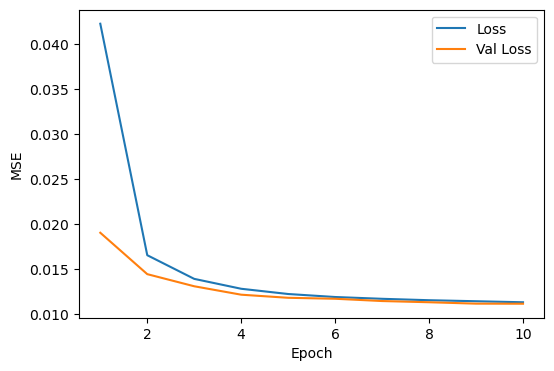

In [13]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), train_losses, label='Loss')
plt.plot(range(1, 11), val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

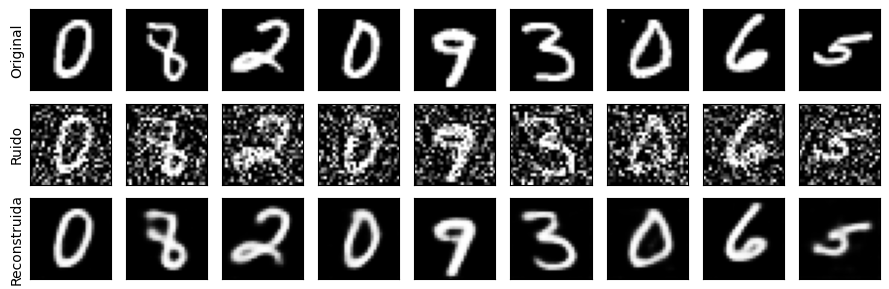

In [14]:
model_ruido.eval()

dataiter = iter(data_loader_valid)
images, labels = next(dataiter)
noisy_images = add_noise(images)

with torch.no_grad():
    recon = model_ruido(noisy_images)

plt.figure(figsize=(9, 3))
plt.gray()

for i in range(9):
    plt.subplot(3, 9, i+1)
    plt.imshow(images[i][0])
    plt.xticks([]); plt.yticks([])
    if i == 0: plt.ylabel('Original')

    plt.subplot(3, 9, 9+i+1)
    plt.imshow(noisy_images[i][0])
    plt.xticks([]); plt.yticks([])
    if i == 0: plt.ylabel('Ruido')

    plt.subplot(3, 9, 18+i+1)
    plt.imshow(recon[i][0])
    plt.xticks([]); plt.yticks([])
    if i == 0: plt.ylabel('Reconstruida')

plt.tight_layout()
plt.show()